# Classification - TAB

In [1]:
# Import libraries
import math
import numpy as np
import pandas as pd
import seaborn as sns
import scipy.stats as stats
import matplotlib.pyplot as plt
from pyexpat import features
from scipy.stats import pearsonr
import matplotlib.colors as mcolors

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, export_graphviz
import pydotplus
from IPython.display import Image
import graphviz
import dtreeviz



In [2]:
patients_df = pd.read_csv('../datasets/general_patients_TAB.csv')
patients_df.head()

,study_id,subject_id,diagnosis,gender,age,dod,age_range,diagnosis_categories,num_categories,temperature_min,...,temperature_class_max,o2sat_class_mean,o2sat_class_min,mean_arterial_pressure_class_mean,mean_arterial_pressure_class_min,mean_arterial_pressure_class_max,RR_HR_ratio_class_mean,RR_HR_ratio_class_min,RR_HR_ratio_class_max,age_range_class
0,40689238,10000032,"['K7469', 'E871', 'R64', 'E875', 'I9581', 'J44...",1,52.0,1,40-60,"['A00-B99', 'I00-I99', 'K00-K95', 'V00-Y99', '...",9,97.7,...,normale,normale,basso,normale,ipotensione,normale,Normale,Normale,Normale,50-60
1,48446569,10000117,"['E7800', 'K219', 'Z87442', 'S72012A', 'I341',...",1,57.0,0,40-60,"['M00-M99', 'I00-I99', 'K00-K95', 'G00-G99', '...",9,97.1,...,normale,normale,basso,normale,ipotensione,ipertensione,Normale,Normale,Normale,50-60
2,47218930,10000764,"['R040', 'D696', 'I252', 'E785', 'I214', 'E780...",0,86.0,0,80-100,"['I00-I99', 'N00-N99', 'V00-Y99', 'Z00-Z99', '...",8,97.6,...,normale,normale,basso,normale,normale,normale,Normale,Normale,Normale,80-90
3,42546971,10000980,"['I248', 'E785', 'Z794', 'Z8673', 'J449', 'E11...",1,75.0,1,60-80,"['I00-I99', 'N00-N99', 'Z00-Z99', 'J00-J99', '...",5,94.8,...,normale,normale,normale,ipertensione,normale,ipertensione,Normale,Normale,Alto,70-80
4,40925049,10001176,"['E871', 'R740', 'D649', 'E785', 'I10', 'K219'...",1,64.0,0,60-80,"['I00-I99', 'K00-K95', 'G00-G99', 'D50-D89', '...",8,98.0,...,febbre,normale,basso,normale,normale,normale,Normale,Normale,Normale,60-70


In [3]:
patients_df.columns

Index(['study_id', 'subject_id', 'diagnosis', 'gender', 'age', 'dod',
       'age_range', 'diagnosis_categories', 'num_categories',
       'temperature_min', 'temperature_max', 'temperature_mean', 'o2sat_min',
       'o2sat_mean', 'mean_arterial_pressure_min',
       'mean_arterial_pressure_max', 'mean_arterial_pressure_mean',
       'RR_HR_ratio_min', 'RR_HR_ratio_max', 'RR_HR_ratio_mean',
       'temperature_class_mean', 'temperature_class_min',
       'temperature_class_max', 'o2sat_class_mean', 'o2sat_class_min',
       'mean_arterial_pressure_class_mean', 'mean_arterial_pressure_class_min',
       'mean_arterial_pressure_class_max', 'RR_HR_ratio_class_mean',
       'RR_HR_ratio_class_min', 'RR_HR_ratio_class_max', 'age_range_class'],
      dtype='object')

In [4]:
#check if there is any null value
patients_df.isnull().values.any()

False

Numero di pazienti con 'I00-I99': 27287
Numero di pazienti senza 'I00-I99': 12190


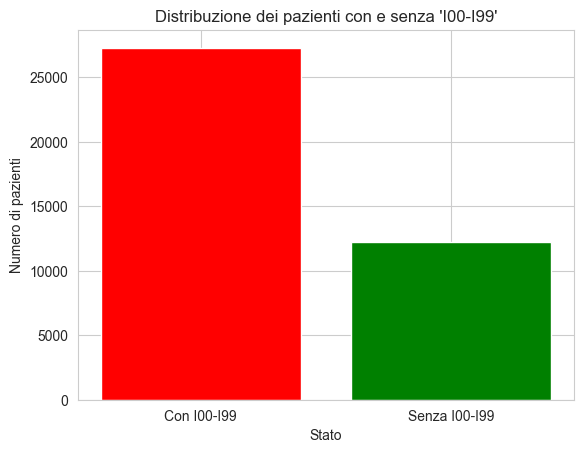

In [3]:
# Verificare se 'I00-I99' è presente in 'diagnosis_categories' e mappare i valori in 1 e 0
patients_df['label'] = patients_df['diagnosis_categories'].apply(lambda x: 1 if 'I00-I99' in x else 0)

# Contare quanti pazienti hanno 'I00-I99' nei diagnosis_categories
count_has_I00_I99 = patients_df['label'].sum()

# Contare quanti non hanno 'I00-I99'
count_no_I00_I99 = len(patients_df) - count_has_I00_I99

# Stampare i risultati
print(f"Numero di pazienti con 'I00-I99': {count_has_I00_I99}")
print(f"Numero di pazienti senza 'I00-I99': {count_no_I00_I99}")

# Visualizzare con un grafico a barre
counts = [count_has_I00_I99, count_no_I00_I99]
labels = ['Con I00-I99', 'Senza I00-I99']

plt.bar(labels, counts, color=['red', 'green'])
plt.title("Distribuzione dei pazienti con e senza 'I00-I99'")
plt.xlabel("Stato")
plt.ylabel("Numero di pazienti")
plt.show()


### Classificazione dei TAB con e senza SMOTE

In [11]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    auc,
)
from imblearn.over_sampling import SMOTE
import matplotlib.pyplot as plt

def classisifaction(USE_SMOTE, test_size):
    # Definisci i classificatori da testare
    classifiers = {
        "Decision Tree": DecisionTreeClassifier(random_state=42),
        "Random Forest": RandomForestClassifier(n_estimators=335, class_weight={0: 1.8, 1: 1}, random_state=42),
        "AdaBoost": AdaBoostClassifier(n_estimators=100, algorithm='SAMME', random_state=42),
        "Logistic Regression": LogisticRegression(max_iter=500),
        "k-NN": KNeighborsClassifier(n_neighbors=5),
    }

    # Definisci le shapelet features da utilizzare
    leads_features = ['age', 'num_categories',
                      'temperature_min', 'temperature_max', 'temperature_mean', 'o2sat_min',
                      'o2sat_mean', 'mean_arterial_pressure_min',
                      'mean_arterial_pressure_max', 'mean_arterial_pressure_mean',
                      'RR_HR_ratio_min', 'RR_HR_ratio_max', 'RR_HR_ratio_mean']

    # Seleziona le features e le etichette
    X = patients_df[leads_features]
    y = patients_df['label']

    # Suddividi il dataset in training e testing
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=test_size, random_state=42)

    # --- Applica SMOTE se USE_SMOTE è True ---
    if USE_SMOTE:
        print("\nApplying SMOTE to balance classes...")
        smote = SMOTE(random_state=42)
        X_train, y_train = smote.fit_resample(X_train, y_train)
    else:
        print("\nSMOTE not applied. Using original training set.")

    # Crea figure per i paragoni affiancati
    fig_confusion, axs_confusion = plt.subplots(1, len(classifiers), figsize=(25, 5))
    fig_pr, axs_pr = plt.subplots(1, len(classifiers), figsize=(25, 5))
    fig_roc, axs_roc = plt.subplots(1, len(classifiers), figsize=(25, 5))

    # Itera sui diversi classificatori
    for i, (name, clf) in enumerate(classifiers.items()):
        print(f"\nProcessing classifier: {name}")

        # Addestra il classificatore
        clf.fit(X_train, y_train)

        # Effettua le predizioni
        y_pred = clf.predict(X_test)

        # Valuta il classificatore
        accuracy = accuracy_score(y_test, y_pred)
        print(f"Accuracy for {name}: {accuracy:.3f}")
        print(classification_report(y_test, y_pred))

        # --- Confusion Matrix ---
        cm = confusion_matrix(y_test, y_pred)
        cm_percent = cm / cm.sum() * 100
        disp = ConfusionMatrixDisplay(confusion_matrix=cm_percent, display_labels=["NO I00_I99", "YES I00_I99"])
        disp.plot(cmap='Blues', values_format='.2f', ax=axs_confusion[i])
        axs_confusion[i].set_title(f"Confusion Matrix ({name})")

        # --- Precision-Recall Curve ---
        if hasattr(clf, "predict_proba"):
            y_scores = clf.predict_proba(X_test)[:, 1]
            precision, recall, thresholds = precision_recall_curve(y_test, y_scores)
            pr_auc = auc(recall, precision)
            axs_pr[i].plot(recall, precision, label=f"PR AUC = {pr_auc:.3f}")
            axs_pr[i].set_title(f"PR Curve ({name})")
            axs_pr[i].set_xlabel("Recall")
            axs_pr[i].set_ylabel("Precision")
            axs_pr[i].legend()

        # --- ROC Curve ---
        if hasattr(clf, "predict_proba"):
            roc_auc = roc_auc_score(y_test, y_scores)
            fpr, tpr, _ = roc_curve(y_test, y_scores)
            axs_roc[i].plot(fpr, tpr, label=f"AUC = {roc_auc:.3f}")
            axs_roc[i].plot([0, 1], [0, 1], linestyle='--', color='gray')
            axs_roc[i].set_title(f"ROC Curve ({name})")
            axs_roc[i].set_xlabel("False Positive Rate")
            axs_roc[i].set_ylabel("True Positive Rate")
            axs_roc[i].legend()

    # Mostra i grafici affiancati con più spazio tra il titolo e i grafici
    plt.tight_layout()
    plt.subplots_adjust(hspace=0.4, wspace=0.4, top=0.85)

    fig_confusion.suptitle(f"Confusion Matrices for Different Classifiers {test_size}\n", fontsize=16)
    fig_pr.suptitle(f"Precision-Recall Curves for Different Classifiers {test_size}\n", fontsize=16)
    fig_roc.suptitle(f"ROC Curves for Different Classifiers {test_size}\n", fontsize=16)

    plt.show()



Testing on test size: 0.2

SMOTE not applied. Using original training set.

Processing classifier: Decision Tree
Accuracy for Decision Tree: 0.734
              precision    recall  f1-score   support

           0       0.57      0.58      0.58      2451
           1       0.81      0.80      0.81      5445

    accuracy                           0.73      7896
   macro avg       0.69      0.69      0.69      7896
weighted avg       0.74      0.73      0.74      7896


Processing classifier: Random Forest
Accuracy for Random Forest: 0.813
              precision    recall  f1-score   support

           0       0.76      0.58      0.66      2451
           1       0.83      0.92      0.87      5445

    accuracy                           0.81      7896
   macro avg       0.80      0.75      0.76      7896
weighted avg       0.81      0.81      0.81      7896


Processing classifier: AdaBoost
Accuracy for AdaBoost: 0.810
              precision    recall  f1-score   support

         

C:\Users\ironl\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression


Accuracy for Logistic Regression: 0.812
              precision    recall  f1-score   support

           0       0.75      0.60      0.66      2451
           1       0.83      0.91      0.87      5445

    accuracy                           0.81      7896
   macro avg       0.79      0.75      0.77      7896
weighted avg       0.81      0.81      0.81      7896


Processing classifier: k-NN
Accuracy for k-NN: 0.780
              precision    recall  f1-score   support

           0       0.68      0.55      0.61      2451
           1       0.81      0.88      0.85      5445

    accuracy                           0.78      7896
   macro avg       0.75      0.72      0.73      7896
weighted avg       0.77      0.78      0.77      7896



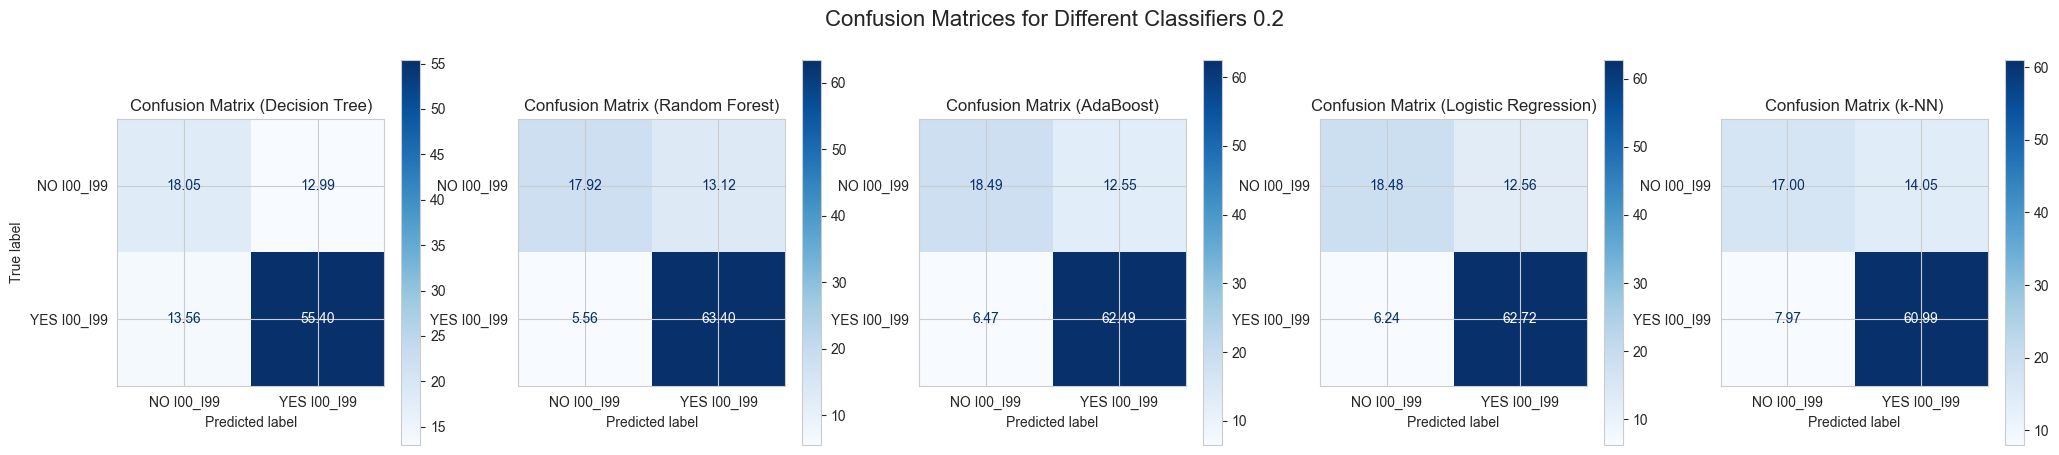

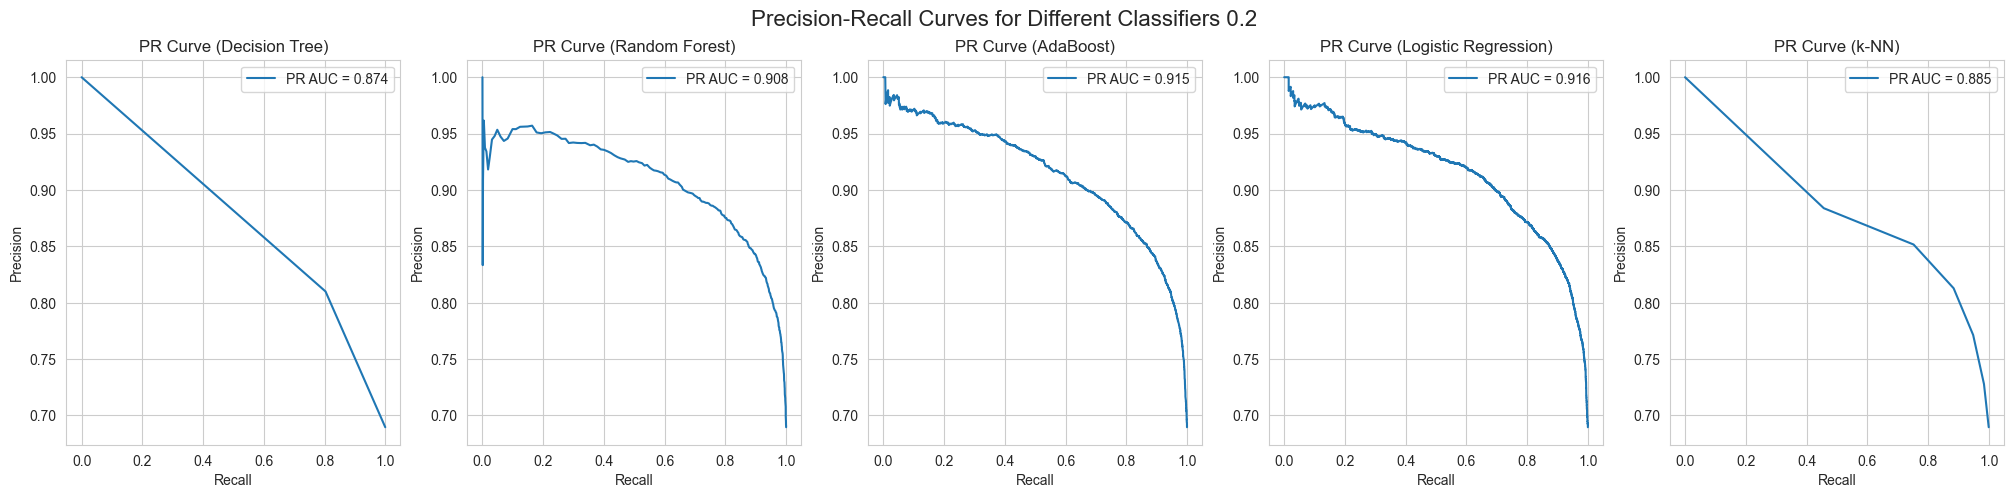

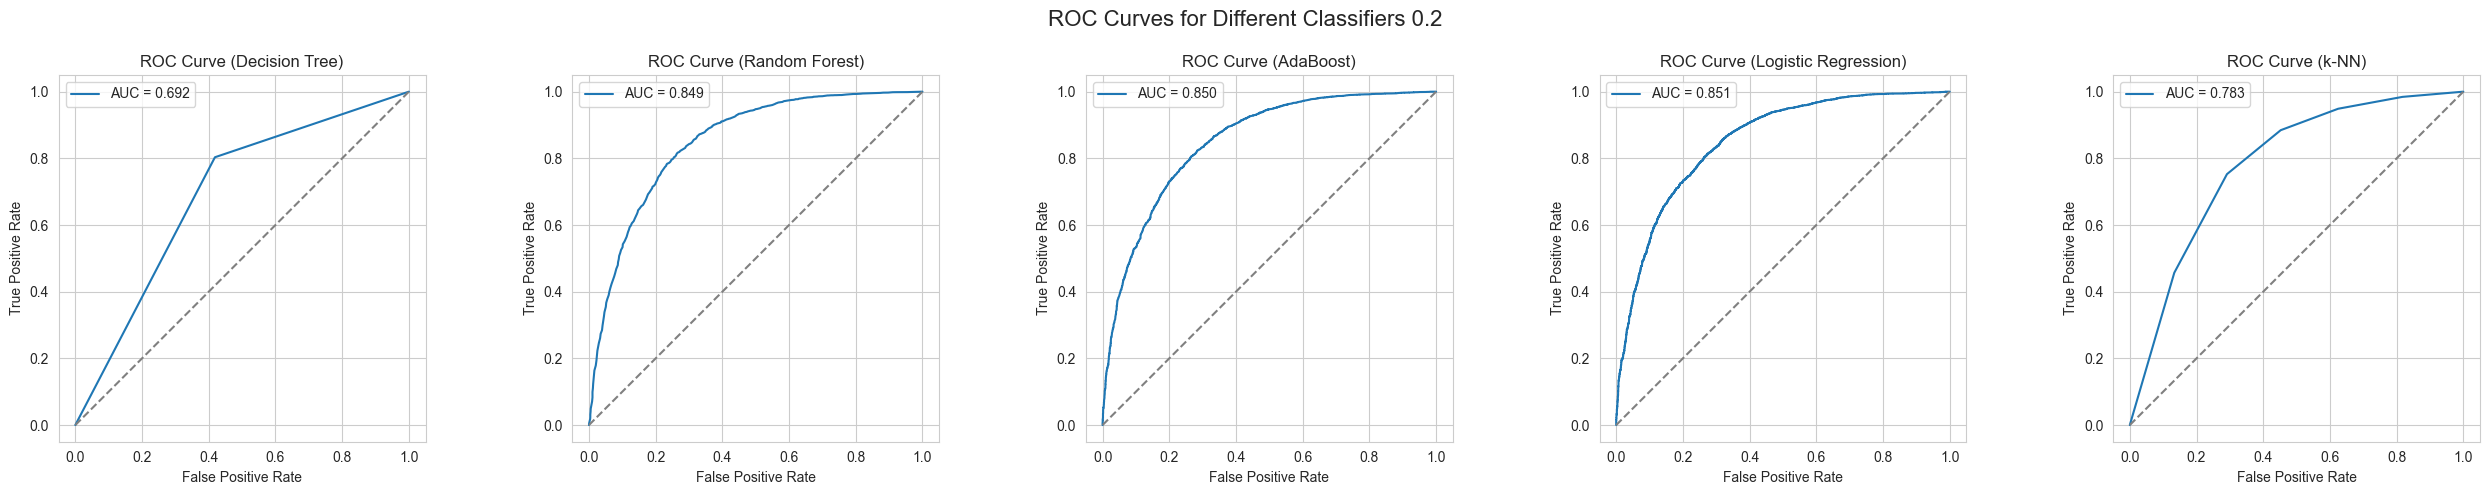


Testing on test size: 0.25

SMOTE not applied. Using original training set.

Processing classifier: Decision Tree
Accuracy for Decision Tree: 0.731
              precision    recall  f1-score   support

           0       0.57      0.58      0.57      3064
           1       0.81      0.80      0.80      6806

    accuracy                           0.73      9870
   macro avg       0.69      0.69      0.69      9870
weighted avg       0.73      0.73      0.73      9870


Processing classifier: Random Forest
Accuracy for Random Forest: 0.818
              precision    recall  f1-score   support

           0       0.77      0.58      0.67      3064
           1       0.83      0.92      0.87      6806

    accuracy                           0.82      9870
   macro avg       0.80      0.75      0.77      9870
weighted avg       0.81      0.82      0.81      9870


Processing classifier: AdaBoost
Accuracy for AdaBoost: 0.811
              precision    recall  f1-score   support

        

C:\Users\ironl\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression


Accuracy for Logistic Regression: 0.812
              precision    recall  f1-score   support

           0       0.74      0.60      0.66      3064
           1       0.83      0.91      0.87      6806

    accuracy                           0.81      9870
   macro avg       0.79      0.75      0.77      9870
weighted avg       0.81      0.81      0.81      9870


Processing classifier: k-NN
Accuracy for k-NN: 0.780
              precision    recall  f1-score   support

           0       0.68      0.55      0.61      3064
           1       0.81      0.88      0.85      6806

    accuracy                           0.78      9870
   macro avg       0.75      0.72      0.73      9870
weighted avg       0.77      0.78      0.77      9870



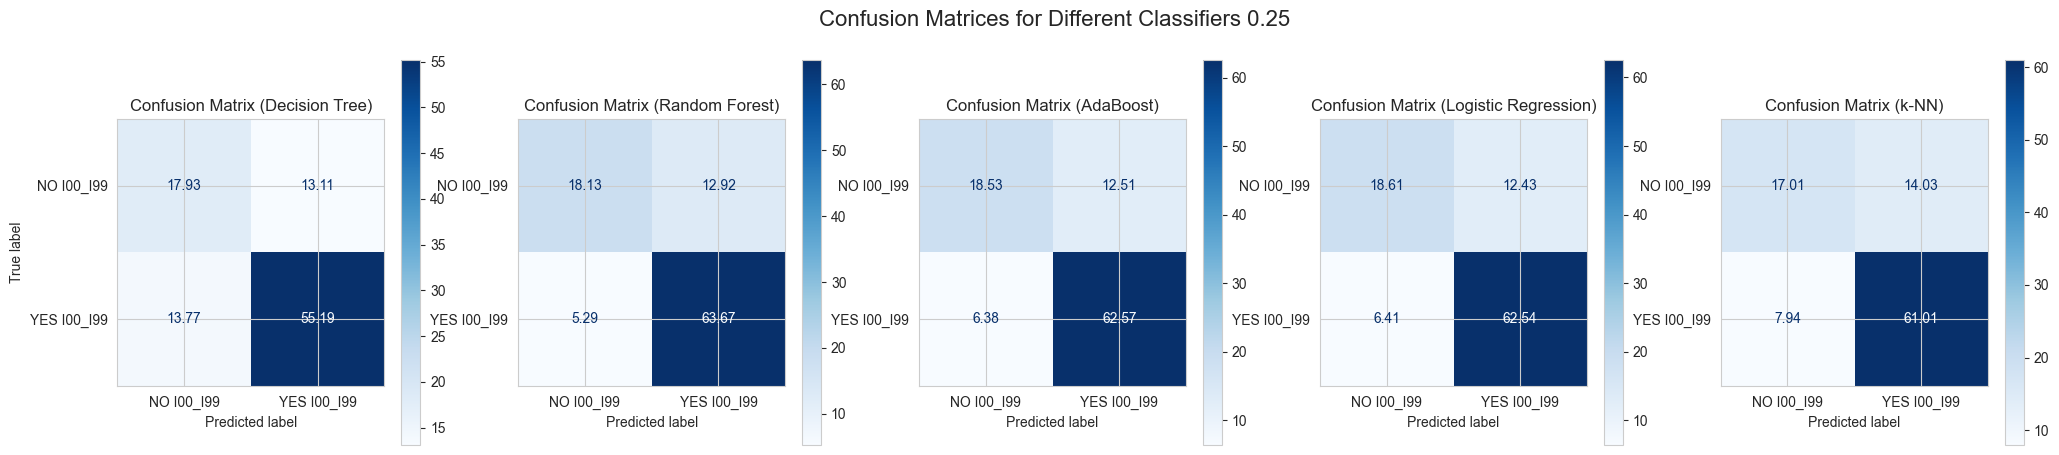

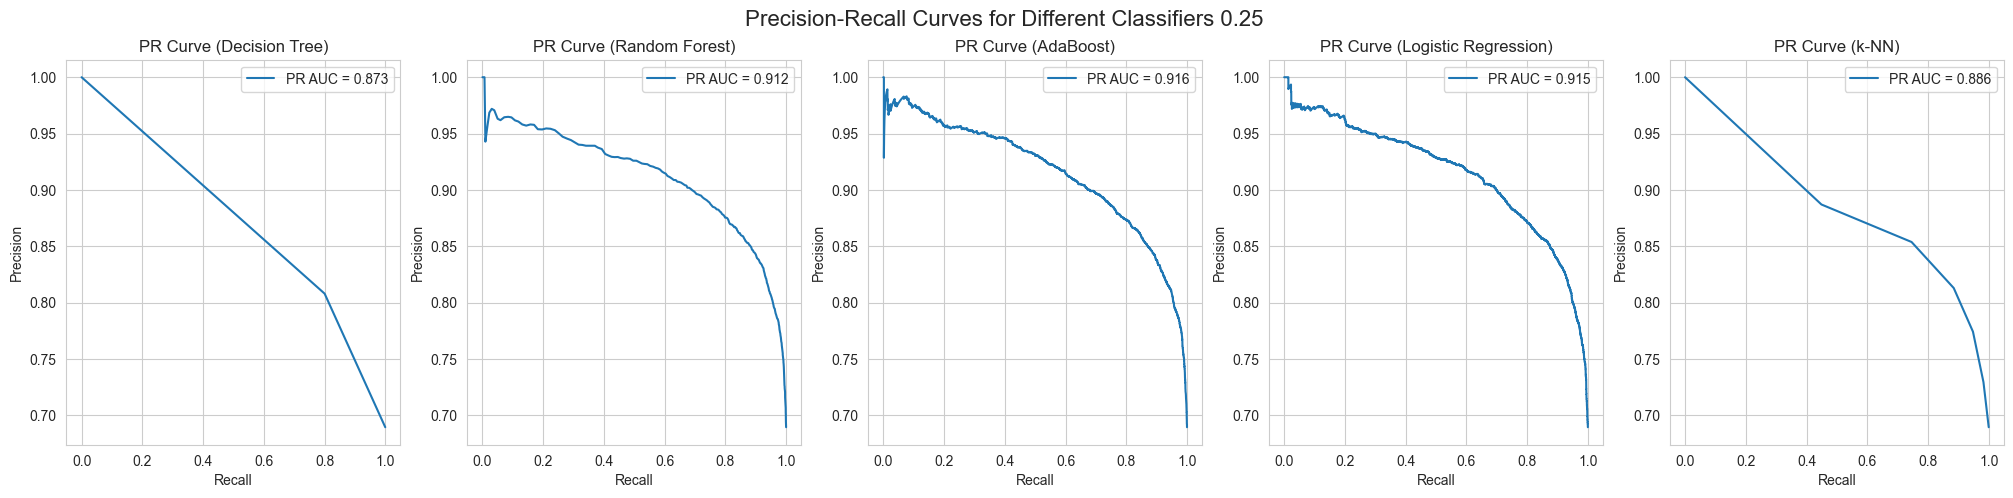

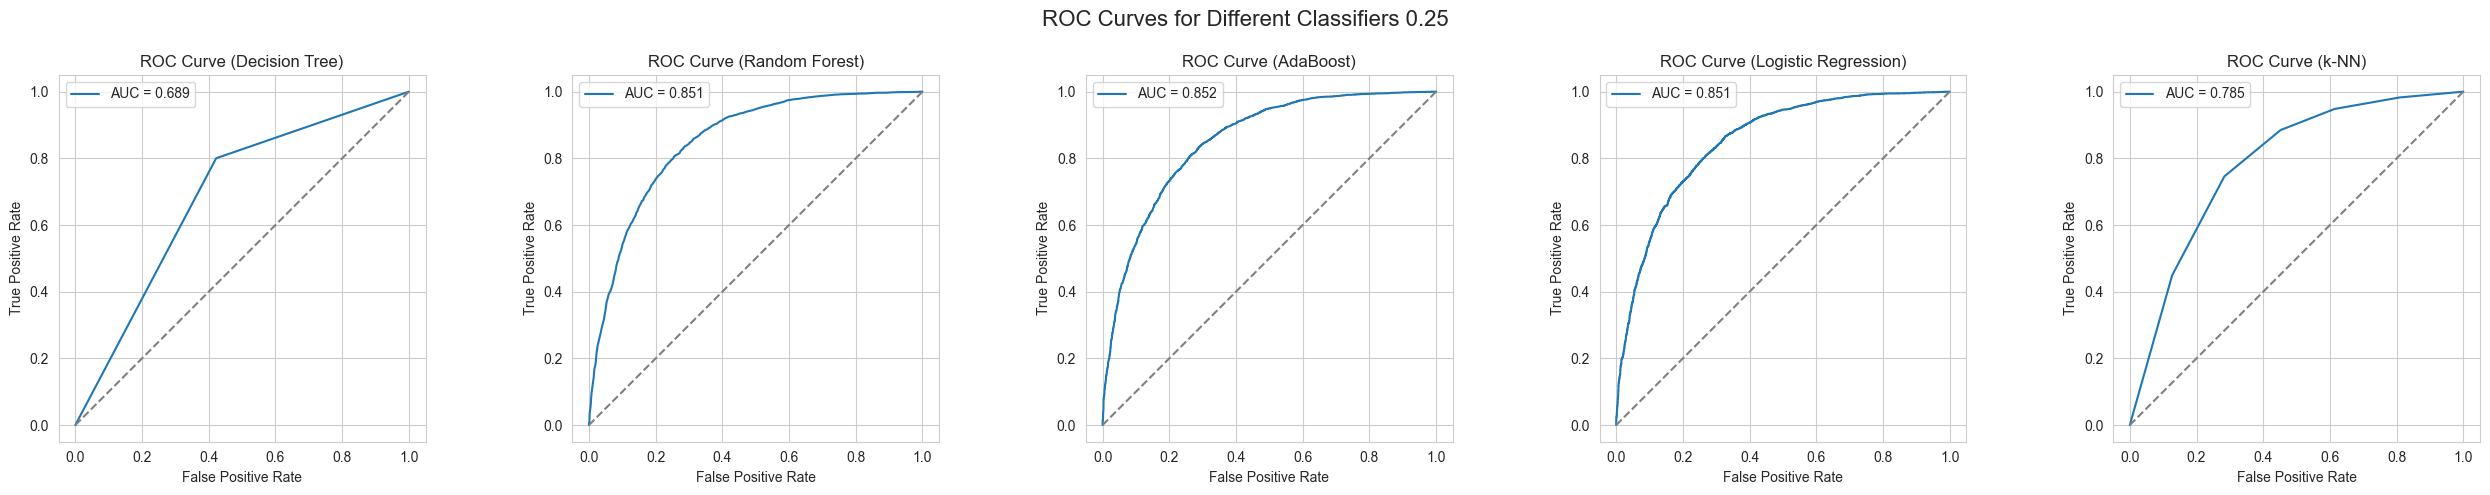


Testing on test size: 0.3

SMOTE not applied. Using original training set.

Processing classifier: Decision Tree
Accuracy for Decision Tree: 0.731
              precision    recall  f1-score   support

           0       0.56      0.57      0.57      3664
           1       0.81      0.80      0.80      8180

    accuracy                           0.73     11844
   macro avg       0.69      0.69      0.69     11844
weighted avg       0.73      0.73      0.73     11844


Processing classifier: Random Forest
Accuracy for Random Forest: 0.813
              precision    recall  f1-score   support

           0       0.76      0.57      0.66      3664
           1       0.83      0.92      0.87      8180

    accuracy                           0.81     11844
   macro avg       0.80      0.75      0.76     11844
weighted avg       0.81      0.81      0.80     11844


Processing classifier: AdaBoost
Accuracy for AdaBoost: 0.811
              precision    recall  f1-score   support

         

C:\Users\ironl\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression


Accuracy for Logistic Regression: 0.812
              precision    recall  f1-score   support

           0       0.74      0.60      0.66      3664
           1       0.84      0.91      0.87      8180

    accuracy                           0.81     11844
   macro avg       0.79      0.75      0.77     11844
weighted avg       0.81      0.81      0.81     11844


Processing classifier: k-NN
Accuracy for k-NN: 0.782
              precision    recall  f1-score   support

           0       0.68      0.55      0.61      3664
           1       0.82      0.88      0.85      8180

    accuracy                           0.78     11844
   macro avg       0.75      0.72      0.73     11844
weighted avg       0.77      0.78      0.77     11844



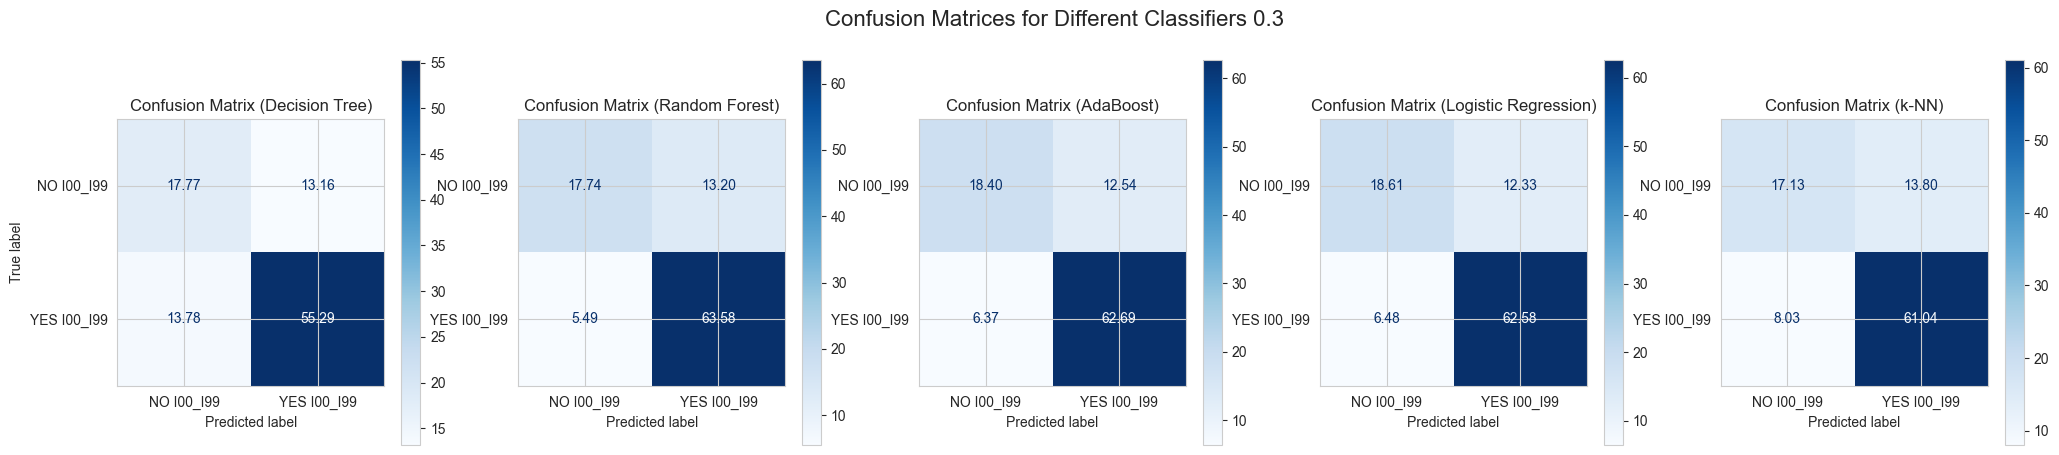

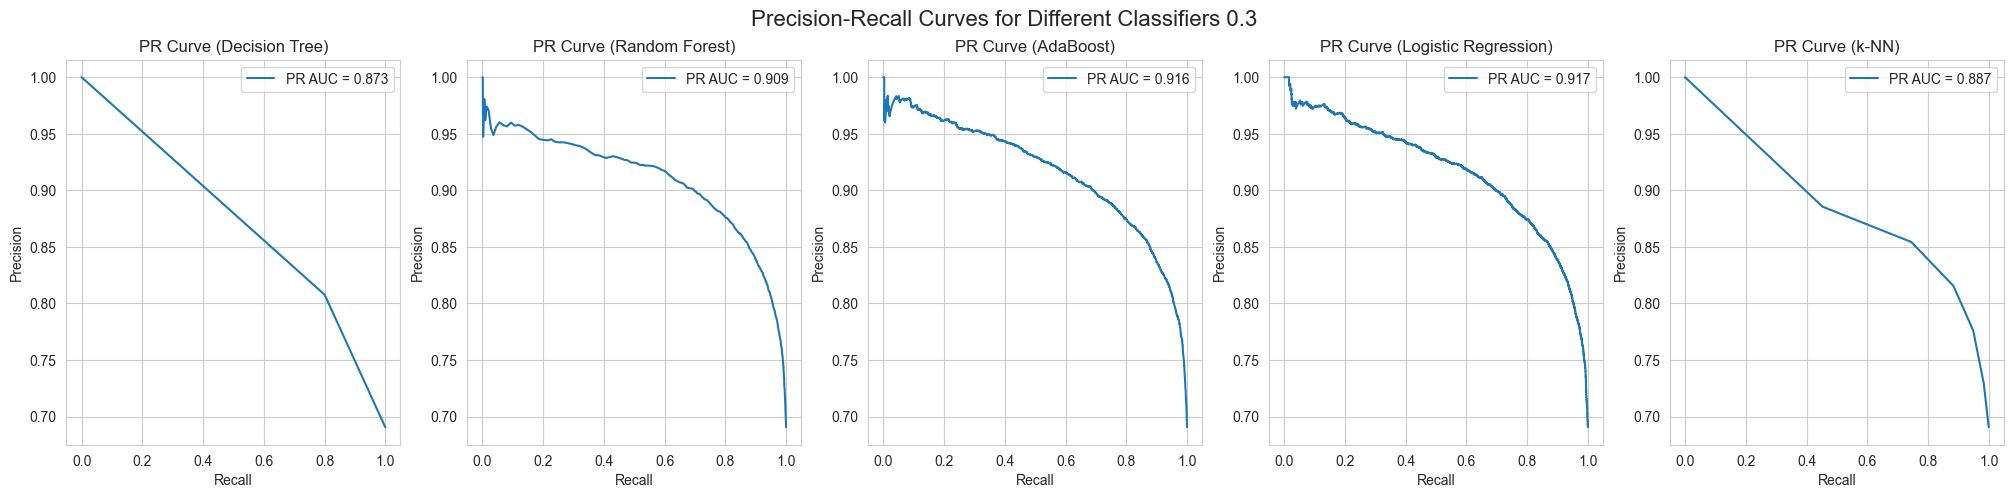

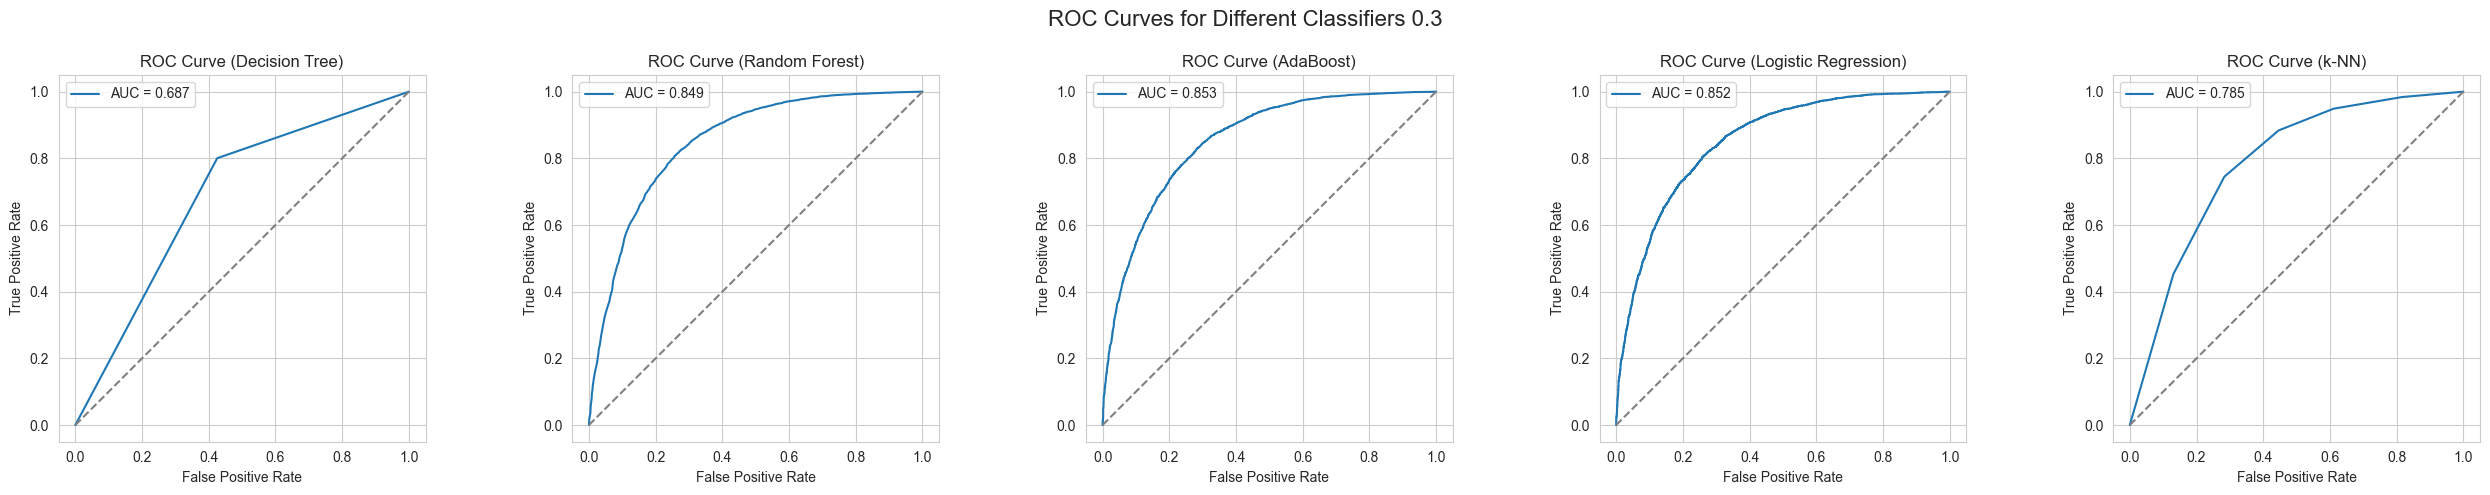

In [12]:
# SMOTE DISATTIVO
test_sizes = [0.20, 0.25, 0.30]
for test_size in test_sizes:
    print("\nTesting on test size:", test_size)
    classisifaction(False, test_size)


Testing on test size: 0.2

Applying SMOTE to balance classes...

Processing classifier: Decision Tree
Accuracy for Decision Tree: 0.708
              precision    recall  f1-score   support

           0       0.52      0.62      0.57      2451
           1       0.81      0.75      0.78      5445

    accuracy                           0.71      7896
   macro avg       0.67      0.68      0.67      7896
weighted avg       0.72      0.71      0.71      7896


Processing classifier: Random Forest
Accuracy for Random Forest: 0.802
              precision    recall  f1-score   support

           0       0.69      0.66      0.67      2451
           1       0.85      0.87      0.86      5445

    accuracy                           0.80      7896
   macro avg       0.77      0.76      0.77      7896
weighted avg       0.80      0.80      0.80      7896


Processing classifier: AdaBoost
Accuracy for AdaBoost: 0.789
              precision    recall  f1-score   support

           0       0

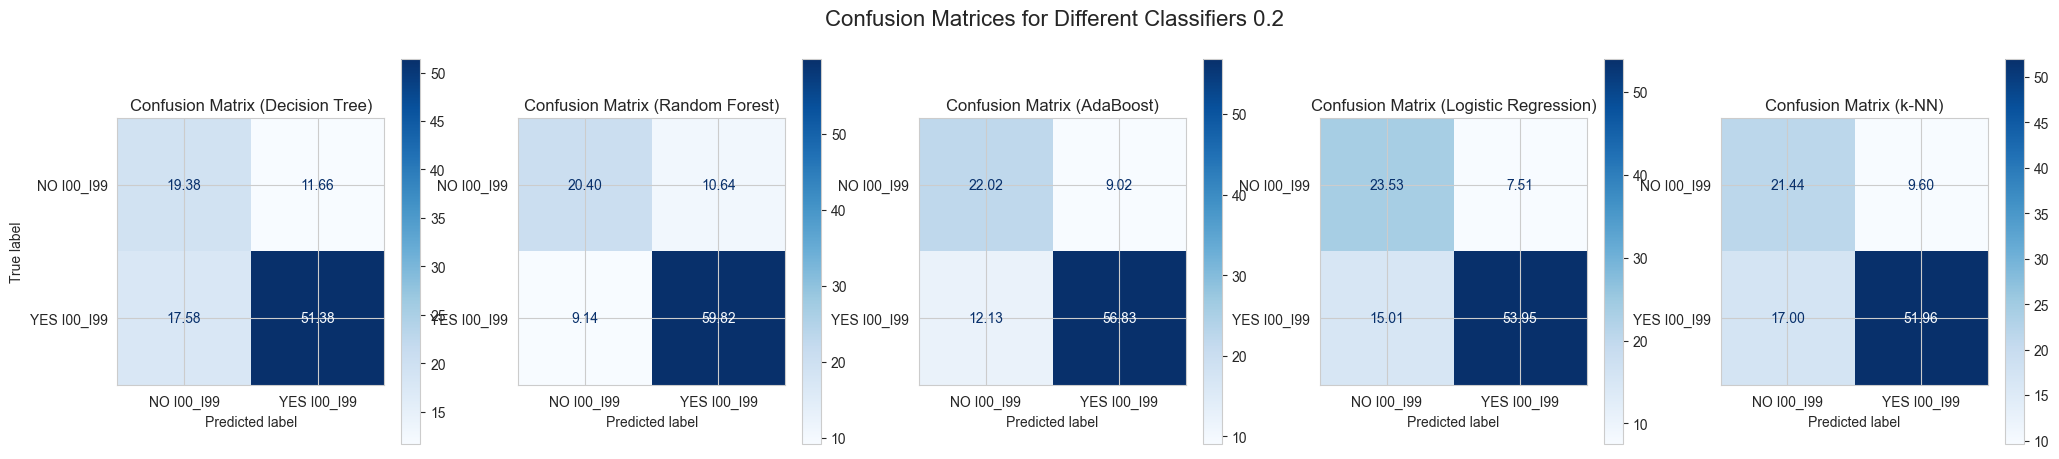

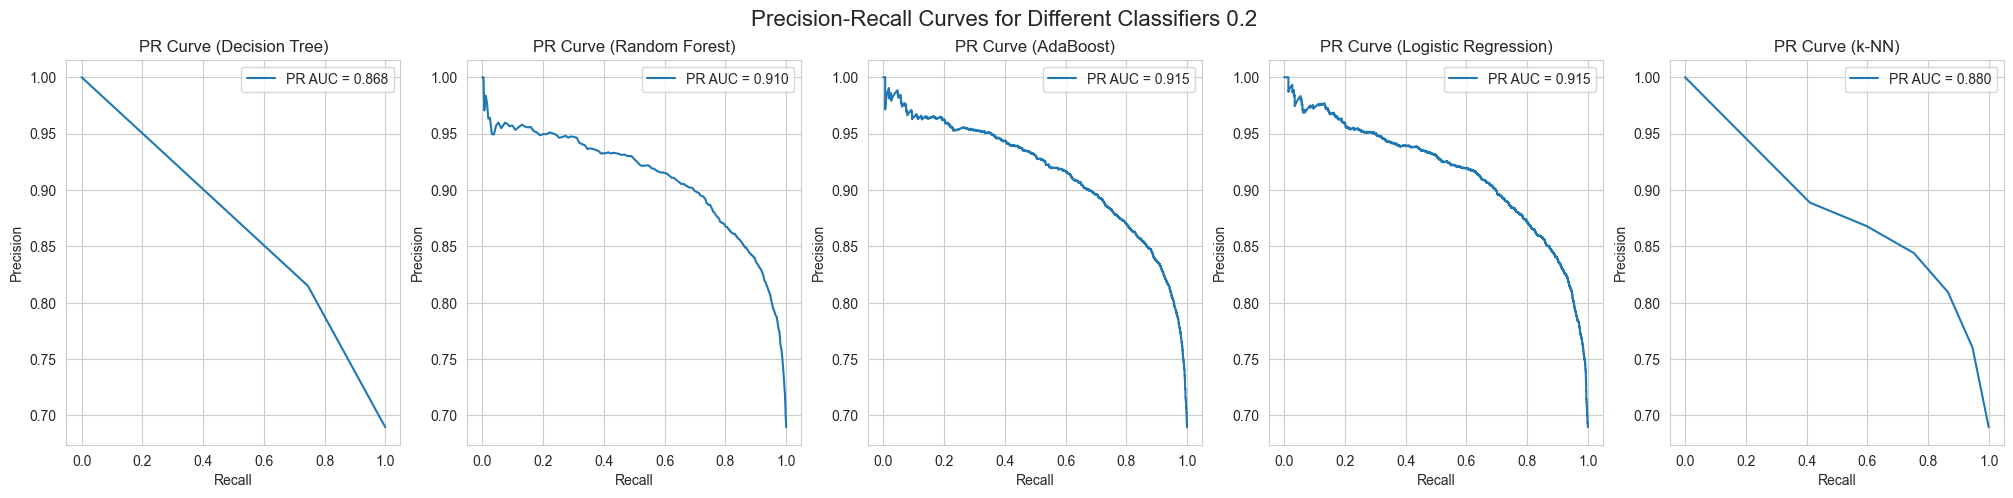

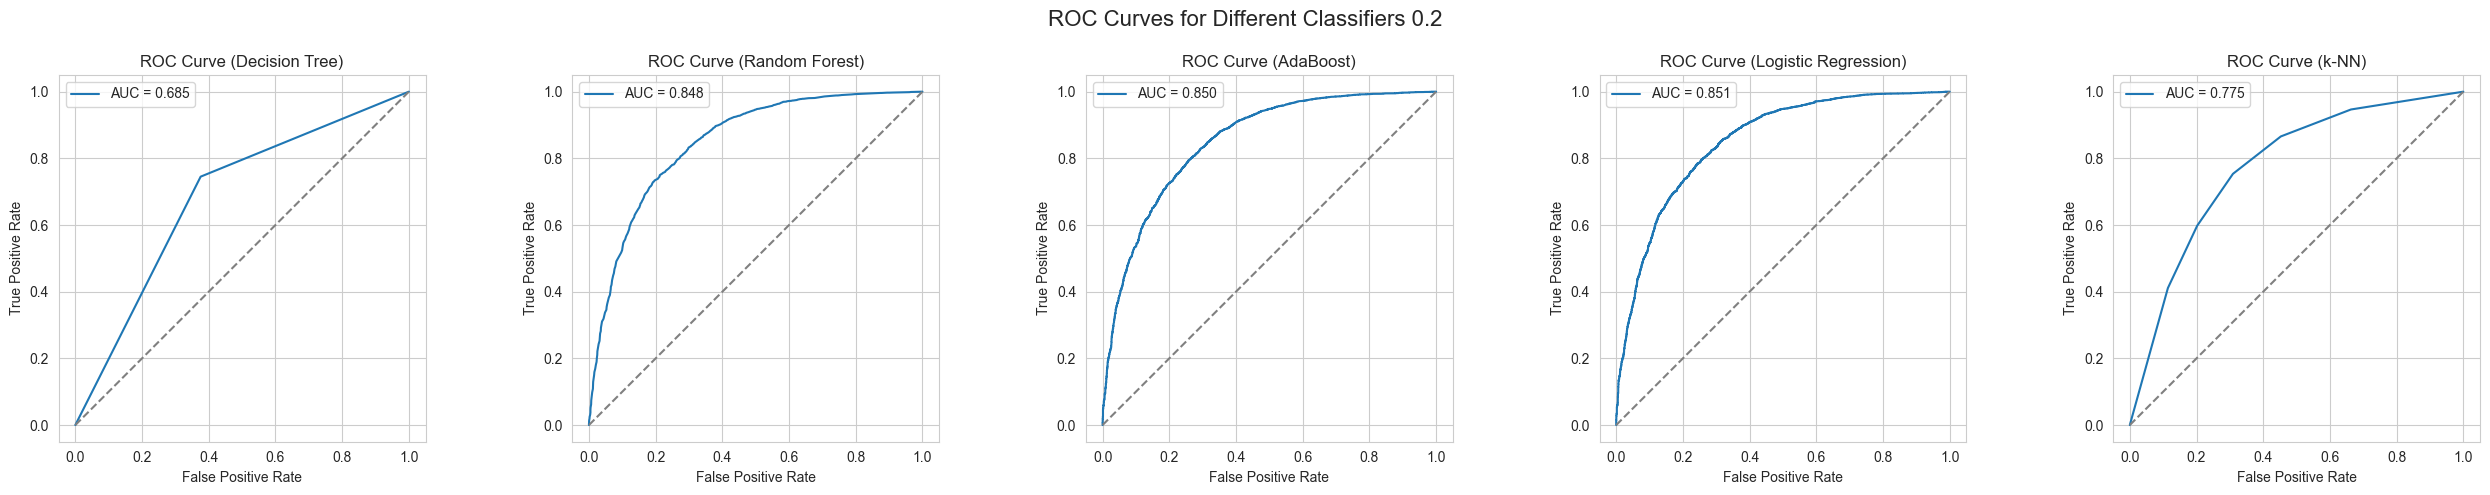


Testing on test size: 0.25

Applying SMOTE to balance classes...

Processing classifier: Decision Tree
Accuracy for Decision Tree: 0.715
              precision    recall  f1-score   support

           0       0.54      0.61      0.57      3064
           1       0.81      0.76      0.79      6806

    accuracy                           0.71      9870
   macro avg       0.67      0.69      0.68      9870
weighted avg       0.73      0.71      0.72      9870


Processing classifier: Random Forest
Accuracy for Random Forest: 0.804
              precision    recall  f1-score   support

           0       0.69      0.66      0.68      3064
           1       0.85      0.87      0.86      6806

    accuracy                           0.80      9870
   macro avg       0.77      0.76      0.77      9870
weighted avg       0.80      0.80      0.80      9870


Processing classifier: AdaBoost
Accuracy for AdaBoost: 0.789
              precision    recall  f1-score   support

           0       

C:\Users\ironl\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression


Accuracy for Logistic Regression: 0.773
              precision    recall  f1-score   support

           0       0.61      0.76      0.68      3064
           1       0.88      0.78      0.83      6806

    accuracy                           0.77      9870
   macro avg       0.74      0.77      0.75      9870
weighted avg       0.79      0.77      0.78      9870


Processing classifier: k-NN
Accuracy for k-NN: 0.728
              precision    recall  f1-score   support

           0       0.55      0.70      0.61      3064
           1       0.84      0.74      0.79      6806

    accuracy                           0.73      9870
   macro avg       0.70      0.72      0.70      9870
weighted avg       0.75      0.73      0.73      9870



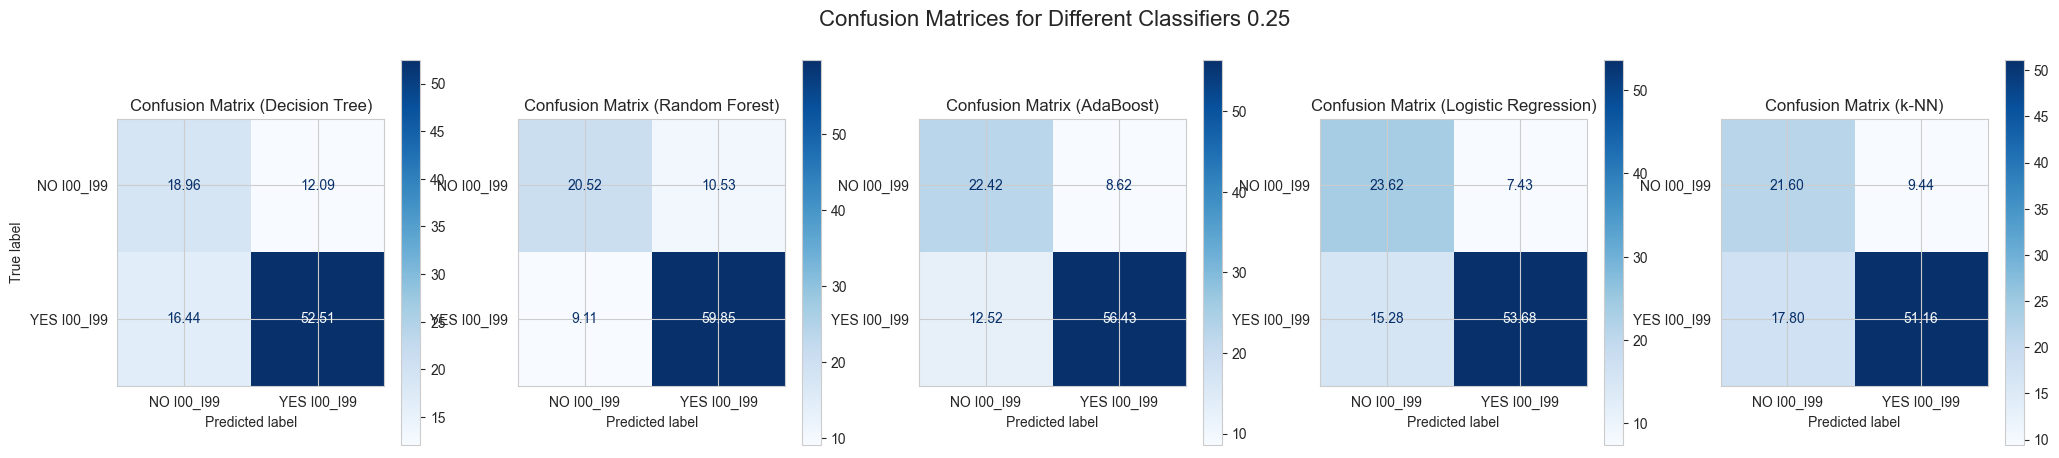

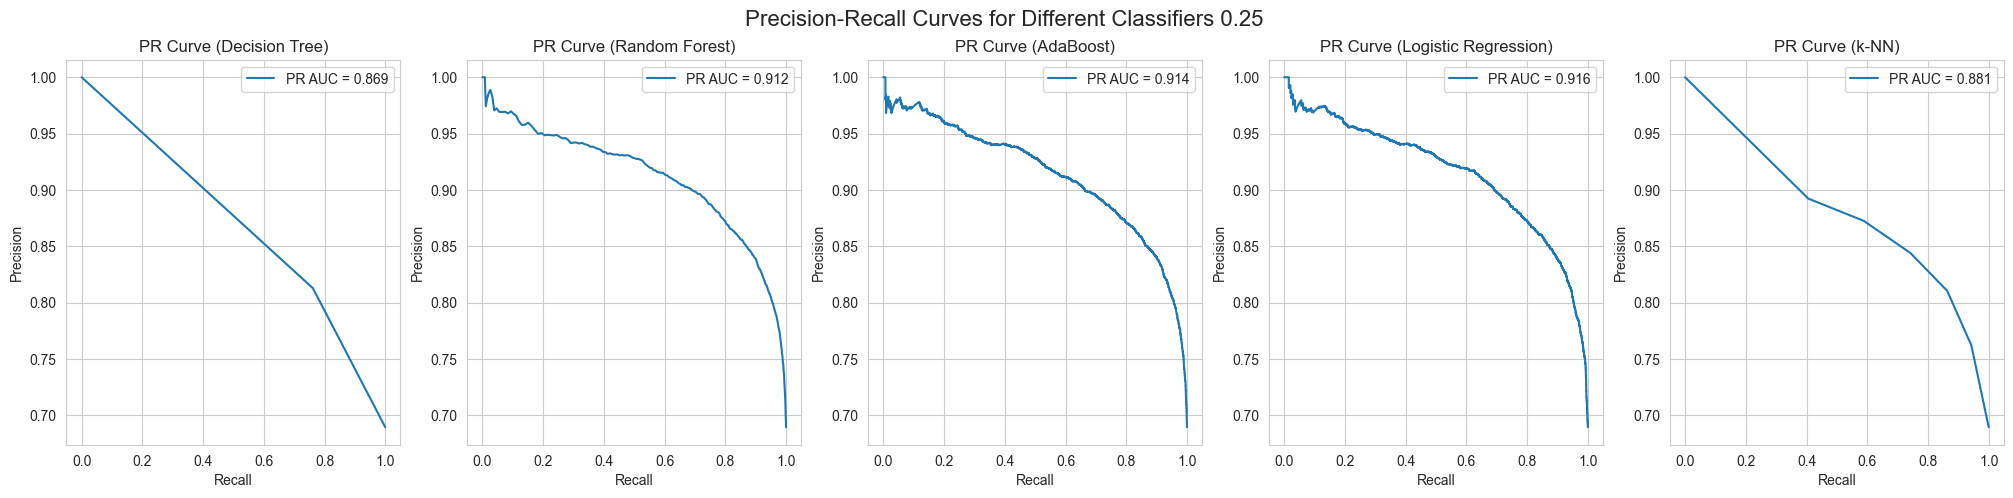

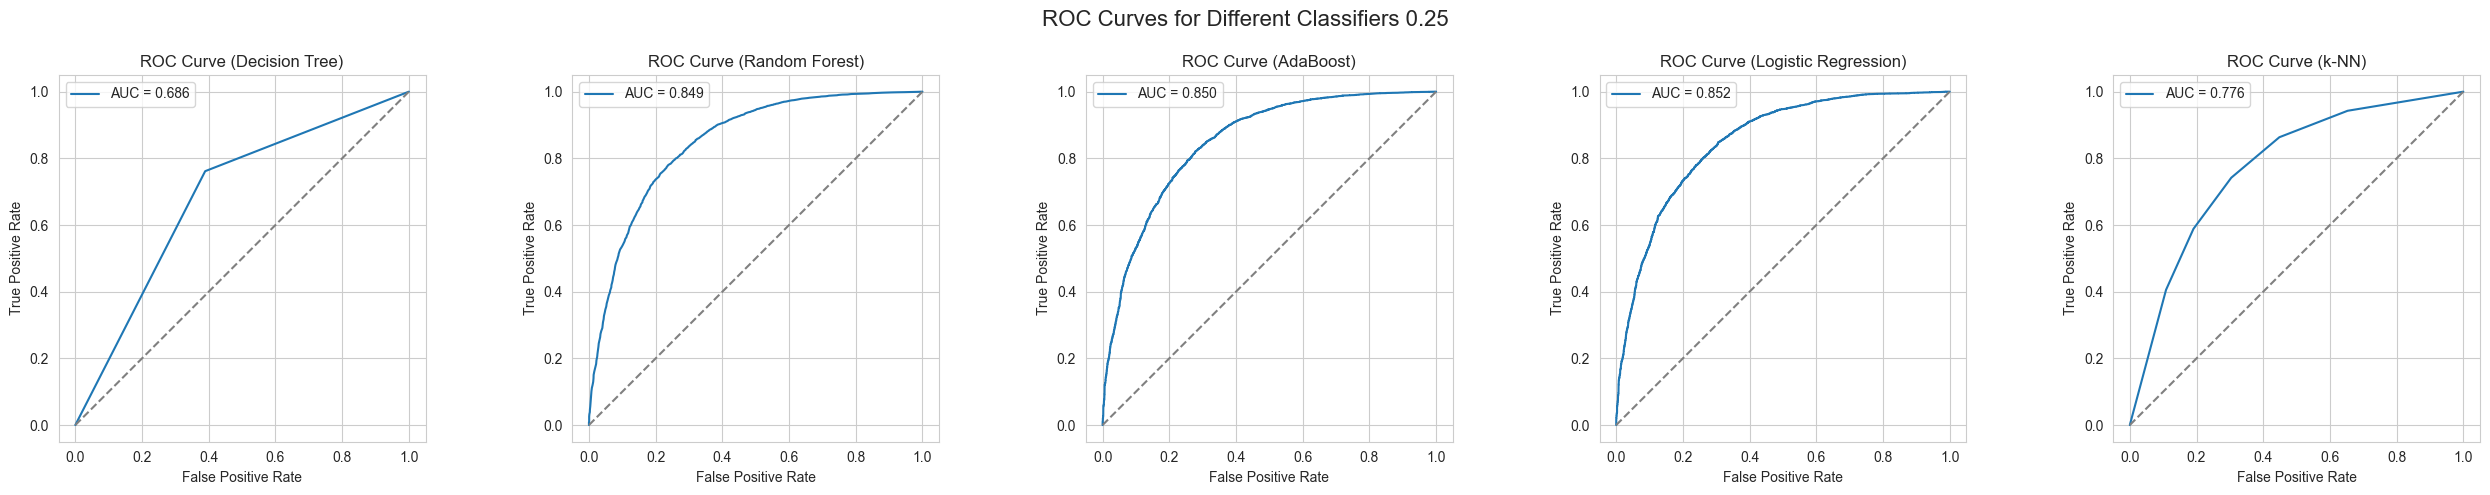


Testing on test size: 0.3

Applying SMOTE to balance classes...

Processing classifier: Decision Tree
Accuracy for Decision Tree: 0.710
              precision    recall  f1-score   support

           0       0.53      0.61      0.57      3664
           1       0.81      0.76      0.78      8180

    accuracy                           0.71     11844
   macro avg       0.67      0.68      0.67     11844
weighted avg       0.72      0.71      0.72     11844


Processing classifier: Random Forest
Accuracy for Random Forest: 0.803
              precision    recall  f1-score   support

           0       0.69      0.66      0.67      3664
           1       0.85      0.87      0.86      8180

    accuracy                           0.80     11844
   macro avg       0.77      0.76      0.77     11844
weighted avg       0.80      0.80      0.80     11844


Processing classifier: AdaBoost
Accuracy for AdaBoost: 0.792
              precision    recall  f1-score   support

           0       0

C:\Users\ironl\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression


Accuracy for Logistic Regression: 0.775
              precision    recall  f1-score   support

           0       0.61      0.76      0.68      3664
           1       0.88      0.78      0.83      8180

    accuracy                           0.77     11844
   macro avg       0.74      0.77      0.75     11844
weighted avg       0.80      0.77      0.78     11844


Processing classifier: k-NN
Accuracy for k-NN: 0.733
              precision    recall  f1-score   support

           0       0.55      0.70      0.62      3664
           1       0.85      0.75      0.79      8180

    accuracy                           0.73     11844
   macro avg       0.70      0.72      0.71     11844
weighted avg       0.76      0.73      0.74     11844



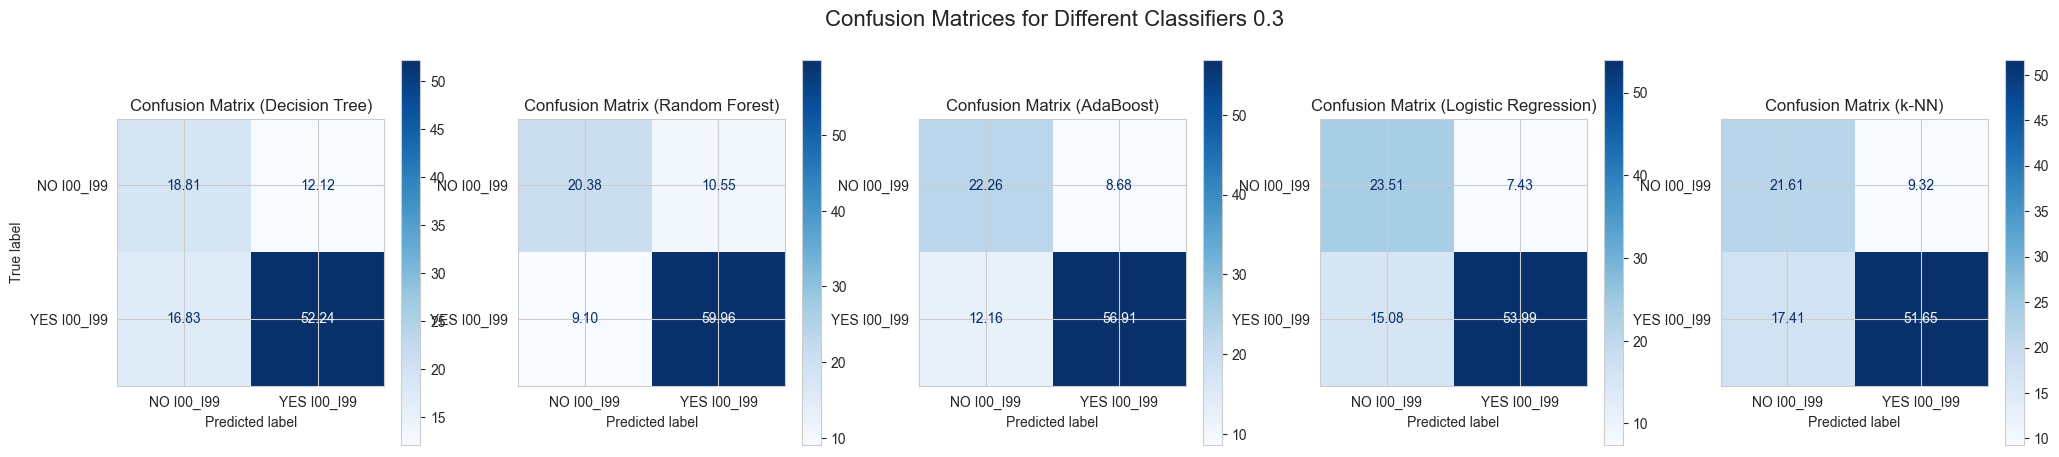

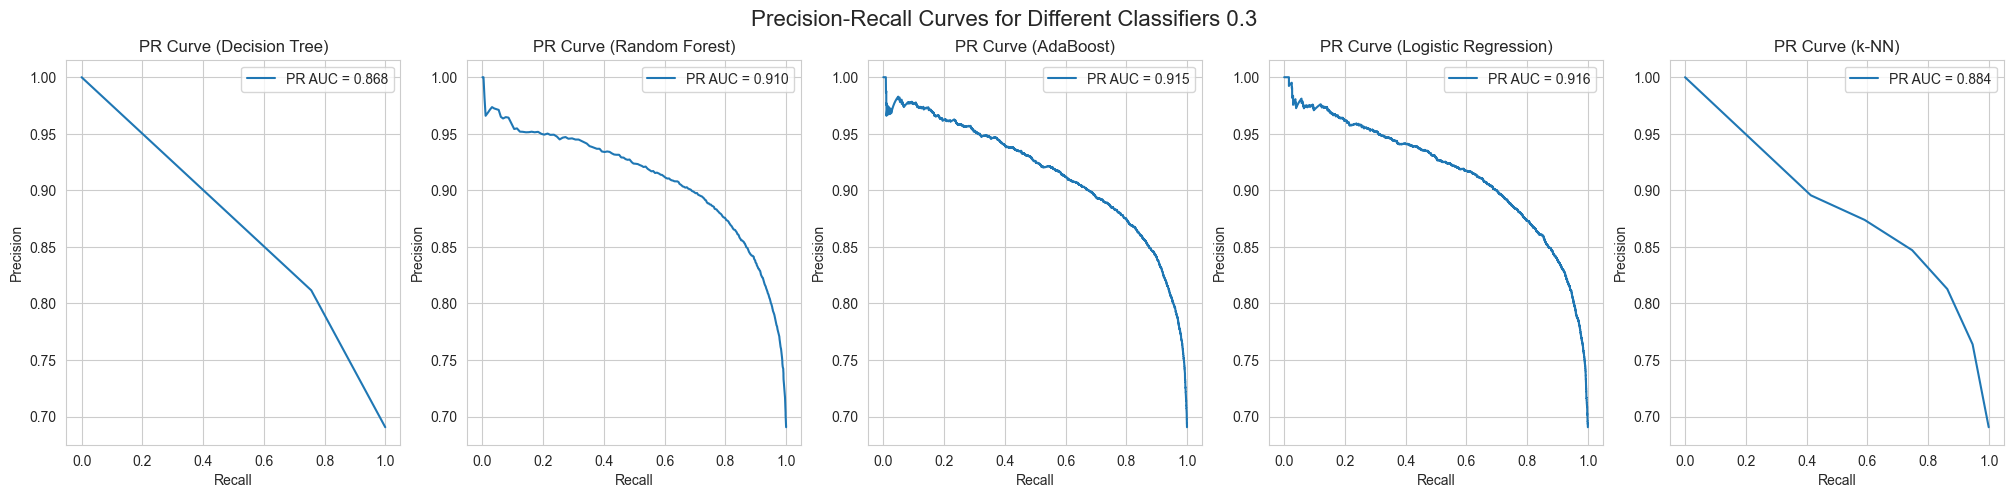

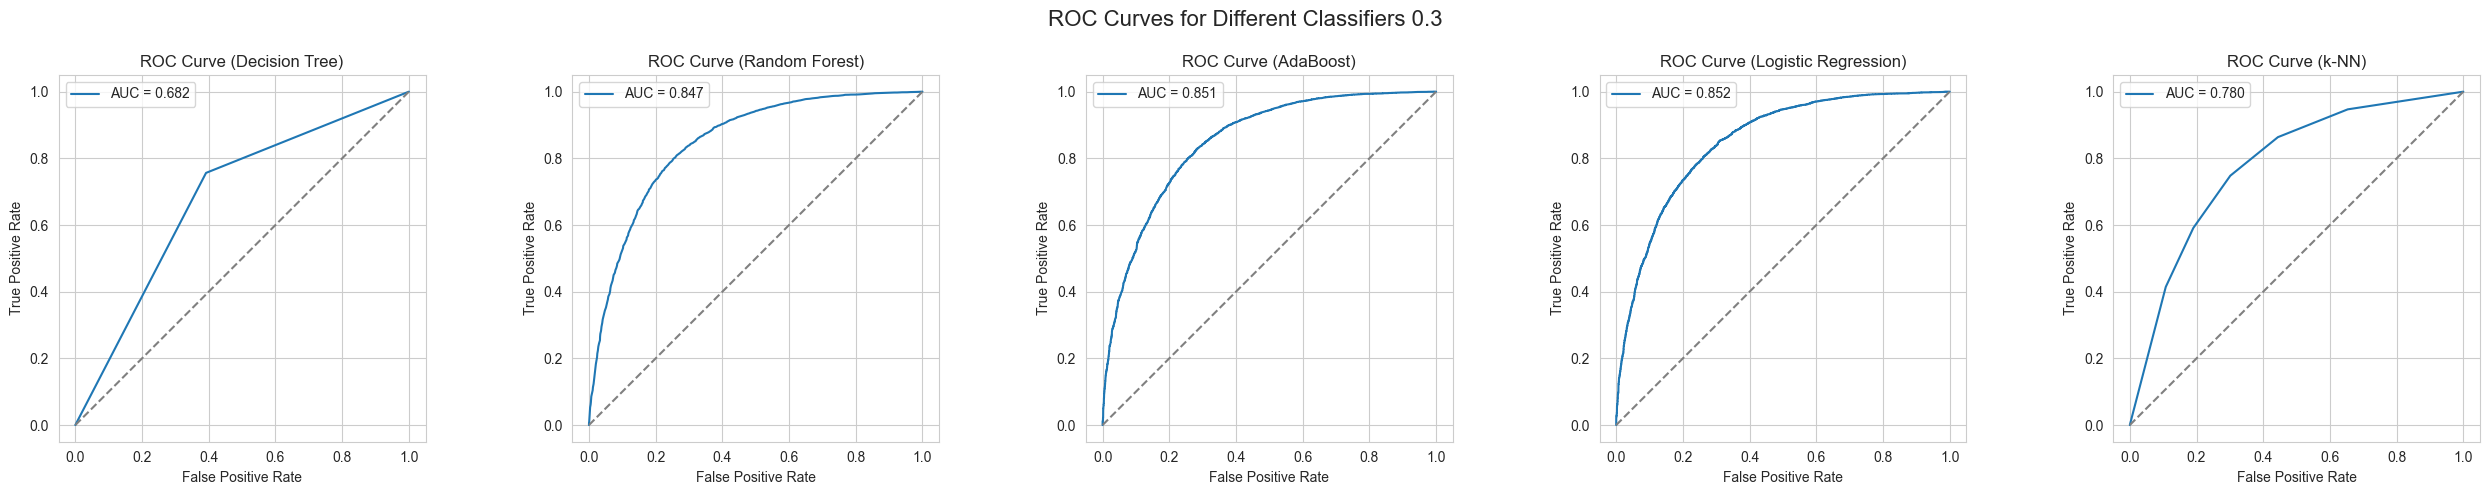

In [13]:
# SMOTE ATTIVO
test_sizes = [0.20, 0.25, 0.30]
for test_size in test_sizes:
    print("\nTesting on test size:", test_size)
    classisifaction(True, test_size)